# Программирование для всех <br>(основы работы с Python)
## Практикум 5: словари, формат JSON и немного графики
*Алла Тамбовцева, НИУ ВШЭ*

### Краткое знакомство с форматом JSON

**JSON** (от *JavaScript Object Notation*) – текстовый формат хранения данных, изначально использовался в языке JavaScript, но затем стал универсальным машиночитаемым форматом, распознаваемым разными языками программирования. Различают:

* JSON-строки (текст с определённой структурой данных внутри);
* JSON-файлы (текстовые файлы с расширением `.json` со строкой JSON-внутри).

Какие структуры данных Python могут встретиться внутри JSON-строки? Знакомые нам списки и словари!

**Пример JSON-строки, содержащей списки:**

In [1]:
# фрагмент результатов голосования в Арбитражный комитет Википедии:
# время голосования, голос, кандидат, избиратель

example01 = """
[["2008-11-23 00:32:00", "-", "Solon", "Kalan"], 
  ["2008-11-23 00:34:00", "+", "Chronicler", "Altes"], 
  ["2008-11-23 00:34:00", "+", "Ilya Voyager", "Altes"]]
"""

**Пример JSON-строки, содержащей словари:**

In [2]:
# фрагмент результатов голосования за актеров
# на сайте kinoteatr.ru

example02 = """
[{"id":"16804", "plus":131, "minus":4, "voted":""},
{"id":"56008", "plus":91, "minus":10, "voted":""},
{"id":"62460", "plus":94, "minus":4, "voted":""}]
"""

Этот формат хранения данных удобен своей универсальностью. Во-первых, он позволяет сохранять и выгружать в компактные текстовые файлы данные со сложной структурой (например, словари, внутри которых есть ещё словари). Во-вторых, формат JSON не привязан к какому-то конкретному языку программирования. Можно создать список списков в Python, выгрузить его в строку JSON, затем считать эту строку с помощью другого языка и получить результат в виде аналогичных структур данных, принятых в этом языке (например, аналогом питоновского словаря `dict` в языке R может выступить поименованный вектор или фрейм `list`).

По этим причинам формат JSON очень популярен. Его можно встретить при работе с географическими данными (файлы с особым расширением `.geojson`, которые содержат метки с координатами объектов), при парсинге HTML-страниц (файлы `.json`, из которых «подтягивается» регулярно обновляемая информация для построения всяких интерактивных визуализаций на сайте) и при подключении к API – интерфейсам, которые можно использовать как базы данных для автоматизированной выгрузки данных из приложений и социальных сетей.

В этом практикуме мы поработаем со строками JSON.

### Чтение JSON-строк с модулем `json`

Импортируем модуль:

In [3]:
import json

В модуле `json` есть две функции, `loads()` и `load()`. Первая преобразует данные из обычной строки (как здесь в примерах выше), вторая – данные, загруженные из файла (будет далее). Преобразование JSON-строки в структуру данных называется **десериализацией JSON**. 

Так, мы можем преобразовать строку в `example01` в список списков:

In [4]:
res01 = json.loads(example01)
print(res01)
print(type(res01), type(res01[0]))

[['2008-11-23 00:32:00', '-', 'Solon', 'Kalan'], ['2008-11-23 00:34:00', '+', 'Chronicler', 'Altes'], ['2008-11-23 00:34:00', '+', 'Ilya Voyager', 'Altes']]
<class 'list'> <class 'list'>


А строку в `example02` – в список словарей:

In [5]:
res02 = json.loads(example02)
print(res02)
print(type(res02), type(res02[0]))

[{'id': '16804', 'plus': 131, 'minus': 4, 'voted': ''}, {'id': '56008', 'plus': 91, 'minus': 10, 'voted': ''}, {'id': '62460', 'plus': 94, 'minus': 4, 'voted': ''}]
<class 'list'> <class 'dict'>


> Мини-задание: вычислите «рейтинг» первого актера (id = 16804), считая, что рейтинг вычисляется как число лайков минус число дизлайков.

In [6]:
res02[0]["plus"] - res02[0]["minus"]

127

### Чтение JSON-строк из результатов запросов с модулем `requests` и немного графиков

Очень часто данные, которые используются для построения интерактивных таблиц и графиков на сайтах, хранятся в виде JSON-строки прямо внутри кода HTML или JSON-файла, ссылку на который тоже можно найти в коде HTML. Импортируем модуль `requests` для запросов:

In [7]:
import requests

Посмотрим на пример данных в виде JSON-строки на странице с оценками фильма пользователей сайта Кинопоиск. Сначала познакомимся с самой страницей:

* откроем [страницу](https://www.kinopoisk.ru/film/43817/?socialAlias=MTY4NjU0OTE5) фильма «Сказка странствий»
* заметим, что с нее можно перейти на с рейтингом и оценками
* откроем исходный код страницы и найдем через поиск (`.json`) по странице ссылку на JSON-файл, откуда подгружаются данные для построения кольцевой диаграммы.

Отправим запрос к этой странице:

In [8]:
# запасная ссылка, если не откроется соединение
# https://raw.githubusercontent.com/allatambov/PyAll26/refs/heads/main/value-stats.json

page = requests.get("https://kinopoisk-fvs.s3.yandex.net/films/43817/value-stats.json")
page # код 200 – ответ получен

<Response [200]>

Запросим текст страницы:

In [9]:
print(page.text)

[{"value":129,"title":"1","out":null},{"value":62,"title":"2","out":null},{"value":96,"title":"3","out":null},{"value":155,"title":"4","out":null},{"value":364,"title":"5","out":null},{"value":711,"title":"6","out":null},{"value":1521,"title":"7","out":null},{"value":2212,"title":"8","out":null},{"value":1702,"title":"9","out":null},{"value":3043,"title":"10","out":"true"}]


Превратим текст в JSON-строку и превратим ее в валидный список словарей (десериализуем JSON в Python):

In [10]:
data = page.json()
print(data)
print(type(data))

[{'value': 129, 'title': '1', 'out': None}, {'value': 62, 'title': '2', 'out': None}, {'value': 96, 'title': '3', 'out': None}, {'value': 155, 'title': '4', 'out': None}, {'value': 364, 'title': '5', 'out': None}, {'value': 711, 'title': '6', 'out': None}, {'value': 1521, 'title': '7', 'out': None}, {'value': 2212, 'title': '8', 'out': None}, {'value': 1702, 'title': '9', 'out': None}, {'value': 3043, 'title': '10', 'out': 'true'}]
<class 'list'>


### Задача 1

Представьте, что мы хотим построить столбиковую диаграмму для оценок, поставленных пользователями. Используя `data`, создайте:

* список `names` с оценками от 1 до 10
* список `freqs`  с количеством оценок.

In [11]:
names = [d["title"] for d in data]
freqs = [d["value"] for d in data]
print(names)
print(freqs)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
[129, 62, 96, 155, 364, 711, 1521, 2212, 1702, 3043]


Код ниже импортирует модуль `pyplot` для отрисовки графиков из графической библиотеки `matplotlib` и построит столбиковую диаграмму на основе `names` и `freqs`.

In [12]:
from matplotlib import pyplot as plt

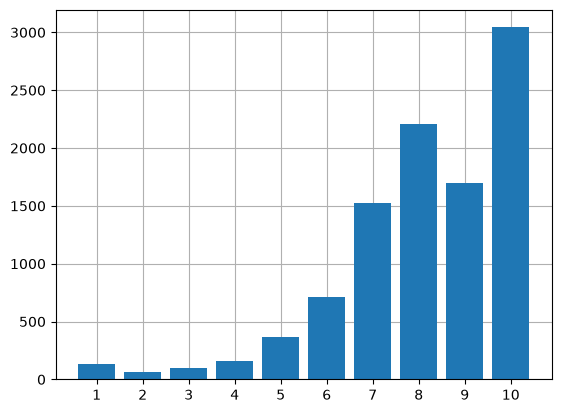

In [13]:
fig, ax = plt.subplots()
ax.bar(names, freqs);
ax.grid();
ax.set_axisbelow(True);

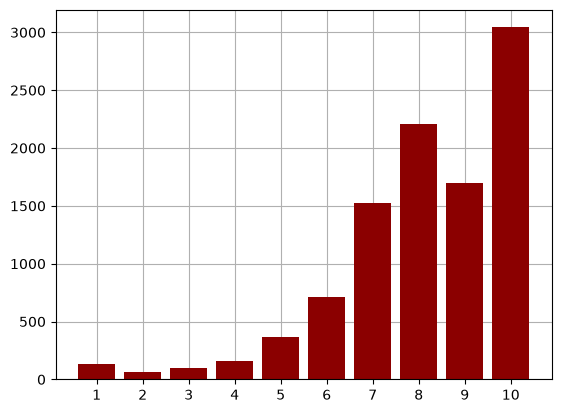

In [14]:
# если изменяем цвет всех столбцов, достаточно 
# указать один цвет в аргументе color

fig, ax = plt.subplots()
ax.bar(names, freqs, color = "darkred");
ax.grid();
ax.set_axisbelow(True);

### Задача 2

Чтобы сделать все столбцы разного цвета, нам придется создать список цветов из 10 названий. Давайте укрупним категории, добавим только четыре цвета для выделения плохих (1-3), удовлетворительных (4-5), хороших (6-7) и отличных (8-10) оценок.

Ниже приведены коды четырех цветов (формат HEX):

* `#45322E`: плохие оценки;
* `#D2691E`: удовлетворительные оценки;
* `#F4A900`: хорошие оценки;
* `#999950`: отличные оценки.

Создайте список `colors`, содержащий цвета для всех столбцов диаграммы. Добавьте цвета на диаграмму – аргумент `color` в `bar()`.

In [15]:
colors = ["#45322E"] * 3 + ["#D2691E"] * 2 + ["#F4A900"] * 2 + ["#999950"] * 3
print(colors)

['#45322E', '#45322E', '#45322E', '#D2691E', '#D2691E', '#F4A900', '#F4A900', '#999950', '#999950', '#999950']


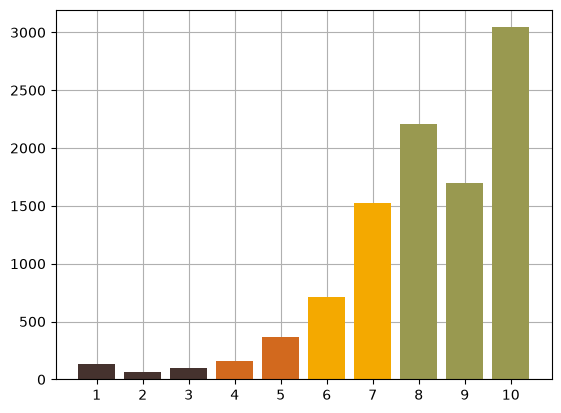

In [16]:
# .grid() – добавляем координатную сетку
# .set_axisbelow(True) – убираем сетку под график, 
# чтобы не перечеркивала столбцы

fig, ax = plt.subplots()
ax.bar(names, freqs, color = colors);
ax.grid();
ax.set_axisbelow(True);

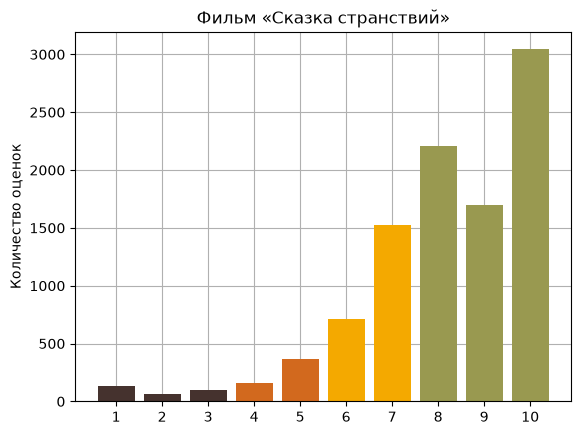

In [17]:
# если хотим добавить название и подписи по осям, применяем к осям ax методы
# .set_title() – заголовок,
# .set_ylabel() – подпись по оси y

fig, ax = plt.subplots()
ax.bar(names, freqs, color = colors);
ax.grid();
ax.set_axisbelow(True);
ax.set_title("Фильм «Сказка странствий»");
ax.set_ylabel("Количество оценок");

### Задача 3

Для построения понятной круговой диаграммы категории точно стоит укрупнить. Например, мы можем объединить оценки в более крупные категории по схеме из задачи 2 (плохие – ниже 4, удовлетворительные – 4 и 5, хорошие – 6 и 7, отличные – выше 7).

Ниже определен словарь `counts`. Используя `data`, измените словарь `counts` таким образом, чтобы на месте значений было записано число соответствующих оценок. Сохраните в `labs` список (тип `list`) ключей, а в `values` – список значений полученного словаря.

In [18]:
counts = {"Плохо" : 0, 
          "Удовлетворительно" : 0, 
          "Хорошо" : 0, 
          "Отлично" : 0}

for d in data:
    if int(d["title"]) < 4:
        counts["Плохо"] += d["value"]
    elif int(d["title"]) < 6:
        counts["Удовлетворительно"] += d["value"]
    elif int(d["title"]) < 8:
        counts["Хорошо"] += d["value"]
    else:
        counts["Отлично"] += d["value"]
print(counts)

{'Плохо': 287, 'Удовлетворительно': 519, 'Хорошо': 2232, 'Отлично': 6957}


In [19]:
labs = list(counts.keys())
values = list(counts.values())
print(labs)
print(values)

['Плохо', 'Удовлетворительно', 'Хорошо', 'Отлично']
[287, 519, 2232, 6957]


Ниже приведен код для построения круговой диаграммы. Приведем ее в более приличный вид вместе!

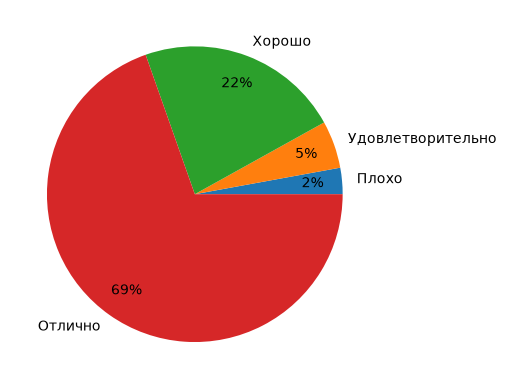

In [20]:
# labels – названия секторов на диаграмме
# autopct – включаем вычисление процентов (%i - округление)
# pctdistance – расстояние от центра круга

fig, ax = plt.subplots()
ax.pie(values, labels = labs, autopct = "%i%%", pctdistance = 0.8);

> Чтобы сделать кольцевую диаграмму, нужно наклеить поверх круговой диаграммы белый круг. Создаем его через функцию `plt.Circle()`: фиксируем центр в точке (0, 0), радиус 0.5, цвет фигуры (`fc` от *face color*) белый. Затем забираем текущее состояние осей на графике через метод `.gca()` (от *get current axes*) и добавляем туда фигуру с помощью метода `.add_artist()` (*artist* – графический элемент, например, круг, прямоугольник или точка).

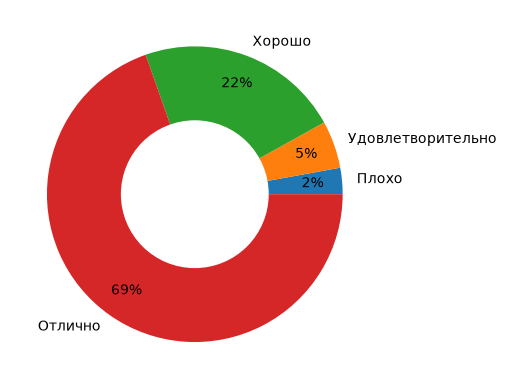

In [21]:
fig, ax = plt.subplots()
ax.pie(values, labels = labs, autopct = "%i%%", pctdistance = 0.8);
ci = plt.Circle((0, 0), 0.5, fc = "white");
fig.gca().add_artist(ci);

### Дополнительно: доработка графика

Изменим цветовую палитру – возьмем четыре цвета из предыдущих задач.

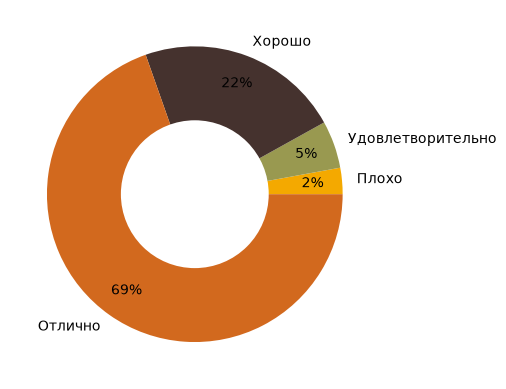

In [22]:
# аргумент colors

cols = ["#F4A900", "#999950", "#45322E", "#D2691E"]

fig, ax = plt.subplots()
ax.pie(values, labels = labs, autopct = "%i%%", 
       pctdistance = 0.8, colors = cols);
ci = plt.Circle((0, 0), 0.5, fc = "white");
fig.gca().add_artist(ci);

Проблема – на темных секторах не видны подписи с процентами. Если мы хотим глобально изменить цвет подписей, это легко, но есть нюансы:

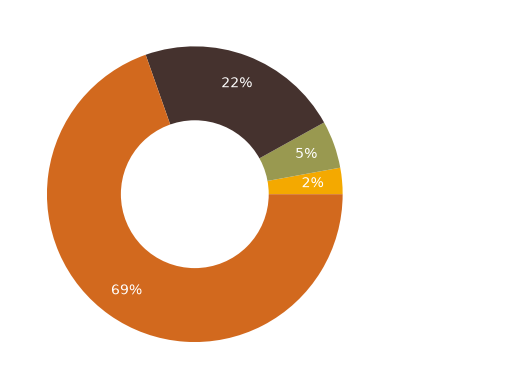

In [23]:
cols = ["#F4A900", "#999950", "#45322E", "#D2691E"]

# добавляем аргумент textprops и фиксируем там цвет в виде словаря

fig, ax = plt.subplots()
ax.pie(values, labels = labs, autopct = "%i%%", pctdistance = 0.8, 
       colors = cols, textprops = {"color":"white"});
ci = plt.Circle((0, 0), 0.5, fc = "white");
fig.gca().add_artist(ci);

Нюансы: 

* все подписи стали белыми, и с названиями секторов тоже, их на белом фоне не видно;
* для нескольких цветов способ уже не подойдет, в `textprops` нельзя добавить список цветов.

Решение проблем одно – разобрать диаграмму на части. Посмотрим на ее составные части:

In [24]:
list(ax.pie(values, labels = labs, autopct = "%i%%", pctdistance = 0.8))

[[<matplotlib.patches.Wedge at 0x1224e4cd0>,
 [Text(1.0955273377824128, 0.09909516724532677, 'Плохо'),
  Text(1.0357221293903944, 0.3705127132650478, 'Удовлетворительно'),
  Text(0.3901399778108025, 1.0284895710282078, 'Хорошо'),
  Text(-0.635465445437384, -0.8978773121396192, 'Отлично')],
 [Text(0.7967471547508457, 0.07206921254205582, '2%'),
  Text(0.7532524577384686, 0.2694637914654893, '5%'),
  Text(0.28373816568058363, 0.747992415293242, '22%'),
  Text(-0.46215668759082473, -0.6530016815560867, '69%')]]

Метод `.pie()` в случае, если добавлены аргументы `labels` и `autopct` возвращает три набора значений: 

*  сектора круга – объекты типа `matplotlib.patches.Wedge`, геометрические фигуры;
*  подписи с названиями секторов – объекты типа `Text`, текст с указанными координатами подписей;
*  подписи с процентами –  объекты типа `Text`, текст с указанными координатами подписей.

Это означает, что мы можем осуществить перебор элементов в нужном нам наборе и применить к ним методы для изменения цвета!

Создадим список нужных цветов для подписей с процентами:

In [25]:
# сектора против часовой стрелки, темный на третьем месте,
# для него делаем белый цвет

pct_colors = ["black", "black", "white", "black"]

Теперь если сохраним результаты `.pie()` в переменные, сможем через `zip()` построить соответствия *подпись с процентами–цвет*  и при переборе таких пар за каждой подписью закрепить свой цвет.

Полный код:

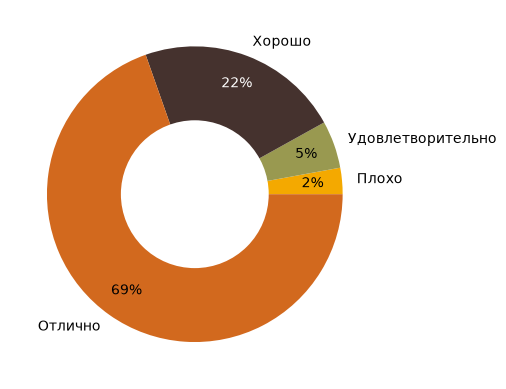

In [26]:
# цвета секторов
# цвета подписей с процентами

cols = ["#F4A900", "#999950", "#45322E", "#D2691E"]
pct_colors = ["black", "black", "white", "black"]

# строим диаграмму и сохраняем ее составные части
# в переменные wedges, texts, pct_texts

fig, ax = plt.subplots()
wedges, texts, pct_texts = ax.pie(values, labels = labs, autopct = "%i%%", pctdistance = 0.8, colors = cols);

# проходим по парам подпись-цвет в zip()
# устанавливаем цвет за каждой подписью

for pct, color in zip(pct_texts, pct_colors):
    pct.set_color(color)

# доклеиваем белый круг как ранее

ci = plt.Circle((0, 0), 0.5, fc = "white");
fig.gca().add_artist(ci);

Последние штрихи – сделаем график побольше, улучшим разрешение изображения, перенесем подписи в легенду, добавим заголовок и экспортируем в файл:

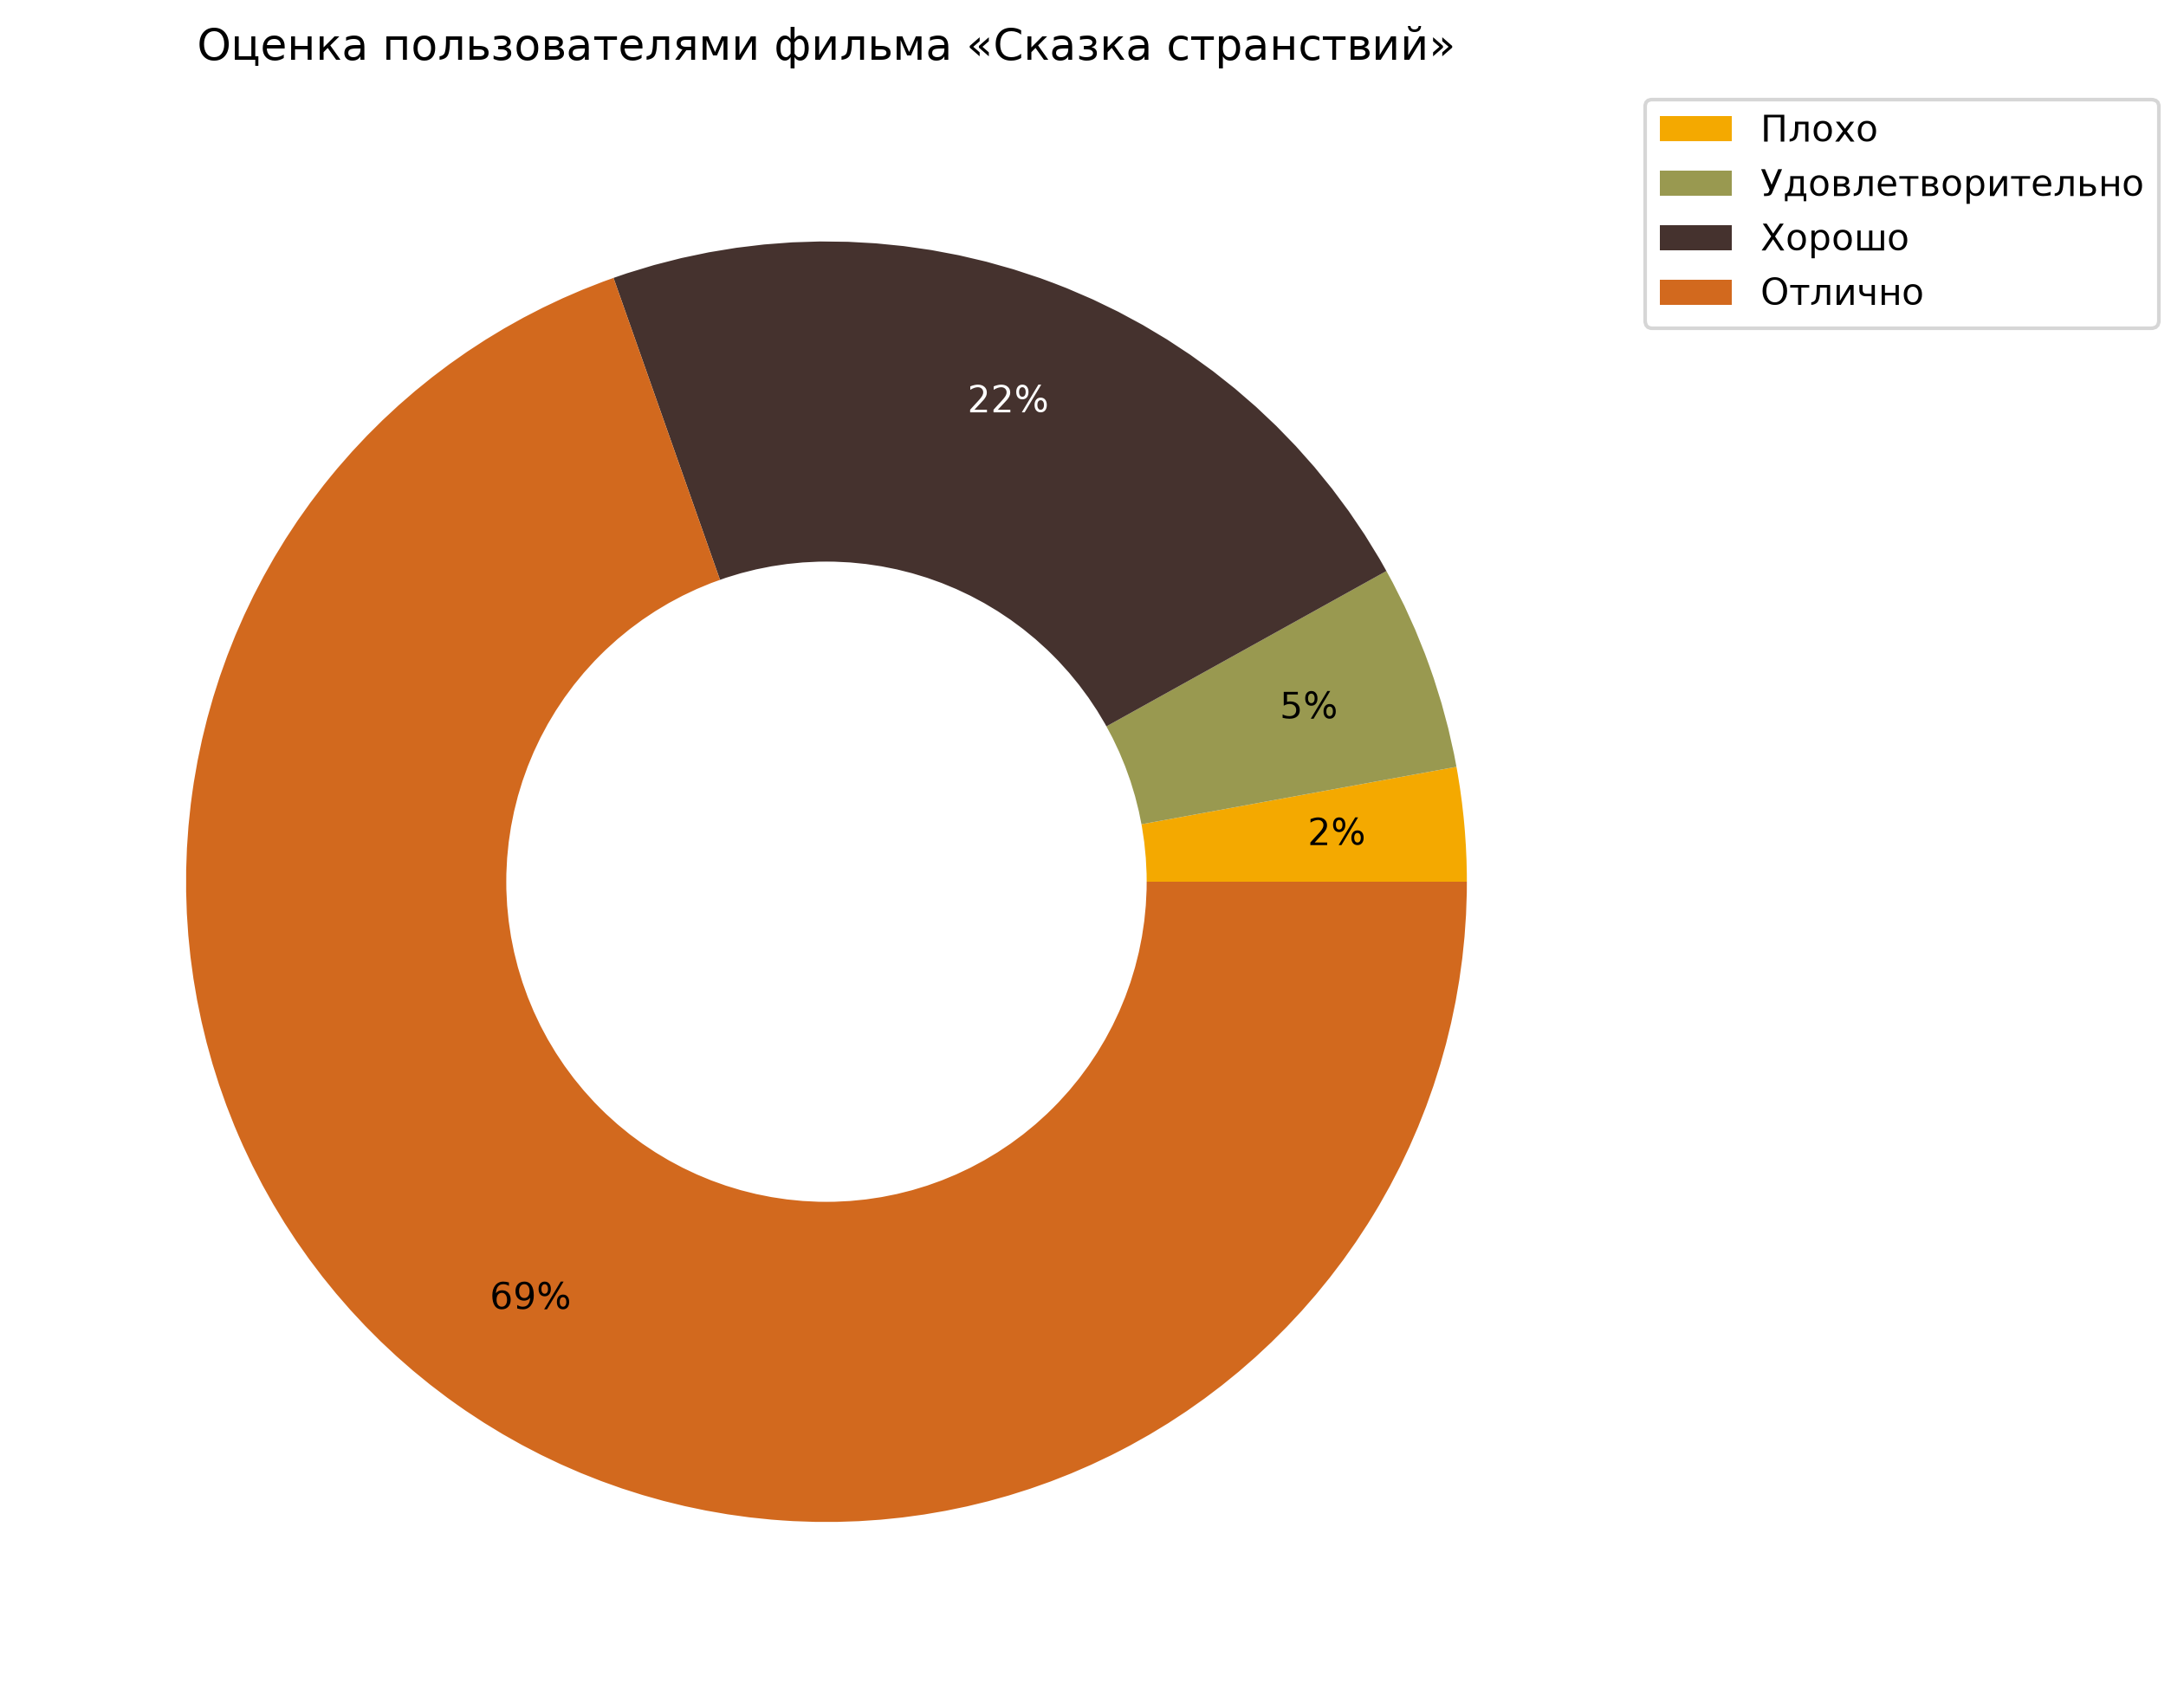

In [27]:
# figsize – размер в дюймах, 
# dpi – число точек на дюйм (разрешение)

fig, ax = plt.subplots(figsize = (8, 8), dpi = 300)

# убираем в .pie() labels = labs, чтобы не было подписей с названиями,
# зато добавляем их в легенду .legend(),
# аргумент bbox_to_anchor – привязка легенды к правому верхнему углу (1, 1)

wedges, texts, pct_texts = ax.pie(values, autopct = "%i%%", pctdistance = 0.8, colors = cols);
ax.legend(labs, bbox_to_anchor = (1, 1));

for pct, color in zip(pct_texts, pct_colors):
    pct.set_color(color)

# добавляем заголовок
ax.set_title("Оценка пользователями фильма «Сказка странствий»")

# доклеиваем белый круг как ранее

ci = plt.Circle((0, 0), 0.5, fc = "white");
fig.gca().add_artist(ci);

# экспортируем в файл
fig.savefig("piechart.png")

Файл с графиком лежит в рабочей папке рядом с текущим ipynb-файлом. Можно запросить путь к рабочей папке и найти там изображение:

In [28]:
import os
print(os.getcwd())

/Users/allat/Documents/Кафедра высшей математики/2026-2027/Python для всех/07-week05
